# Student Depression Case Study

## Problem Statement
Student mental health is a growing concern. This case study analyses the Student Depression dataset to find which factors, such as academic pressure, financial stress, sleep, diet, and study hours, are most linked with depression, and to suggest practical recommendations for students and colleges.

## Tools Used
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn (Jupyter Notebook)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
df = pd.read_csv(r"D:\case study\student_depression_dataset.csv")

In [2]:
import os
print(os.getcwd())
print([f for f in os.listdir() if "cleaned" in f])

D:\case study
['student_depression_cleaned.csv']


## Dataset Description
- The dataset has **27,901 rows and 18 columns**.
- Columns include gender, age, city, profession, academic pressure, CGPA, study satisfaction, sleep duration, dietary habits, degree, suicidal thoughts, work/study hours, financial stress, family history of mental illness, and depression (target: 1 = depressed, 0 = not depressed).
- There were **no duplicate rows** and only **3 missing values** (in Financial Stress).

In [3]:
df.shape

(27901, 18)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     27901 non-null  int64  
 1   Gender                                 27901 non-null  object 
 2   Age                                    27901 non-null  float64
 3   City                                   27901 non-null  object 
 4   Profession                             27901 non-null  object 
 5   Academic Pressure                      27901 non-null  float64
 6   Work Pressure                          27901 non-null  float64
 7   CGPA                                   27901 non-null  float64
 8   Study Satisfaction                     27901 non-null  float64
 9   Job Satisfaction                       27901 non-null  float64
 10  Sleep Duration                         27901 non-null  object 
 11  Di

In [5]:
df.columns.tolist()

['id',
 'Gender',
 'Age',
 'City',
 'Profession',
 'Academic Pressure',
 'Work Pressure',
 'CGPA',
 'Study Satisfaction',
 'Job Satisfaction',
 'Sleep Duration',
 'Dietary Habits',
 'Degree',
 'Have you ever had suicidal thoughts ?',
 'Work/Study Hours',
 'Financial Stress',
 'Family History of Mental Illness',
 'Depression']

In [6]:
df.isnull().sum()

id                                       0
Gender                                   0
Age                                      0
City                                     0
Profession                               0
Academic Pressure                        0
Work Pressure                            0
CGPA                                     0
Study Satisfaction                       0
Job Satisfaction                         0
Sleep Duration                           0
Dietary Habits                           0
Degree                                   0
Have you ever had suicidal thoughts ?    0
Work/Study Hours                         0
Financial Stress                         3
Family History of Mental Illness         0
Depression                               0
dtype: int64

In [7]:

df.duplicated().sum()

np.int64(0)

## Dataset Description
- The dataset has **27,901 rows and 18 columns**.
- Columns include gender, age, city, profession, academic pressure, CGPA, study satisfaction, sleep duration, dietary habits, degree, suicidal thoughts, work/study hours, financial stress, family history of mental illness, and depression (target: 1 = depressed, 0 = not depressed).
- There were **no duplicate rows** and only **3 missing values** (in Financial Stress).

In [8]:
# make column names simple
df.columns = (df.columns.str.strip()
                        .str.lower()
                        .str.replace(" ", "_")
                        .str.replace("/", "_")
                        .str.replace("?", "", regex=False))

# rename the long column
df = df.rename(columns={"have_you_ever_had_suicidal_thoughts_": "suicidal_thoughts"})

# fill 3 missing values with the median
df["financial_stress"] = df["financial_stress"].fillna(df["financial_stress"].median())

# drop the id column (not useful for analysis)
df = df.drop(columns=["id"])

print(df.columns.tolist())
print(df.isnull().sum().sum())

['gender', 'age', 'city', 'profession', 'academic_pressure', 'work_pressure', 'cgpa', 'study_satisfaction', 'job_satisfaction', 'sleep_duration', 'dietary_habits', 'degree', 'suicidal_thoughts', 'work_study_hours', 'financial_stress', 'family_history_of_mental_illness', 'depression']
0


In [9]:
for col in ["gender", "profession", "sleep_duration", "dietary_habits", "degree", "suicidal_thoughts", "family_history_of_mental_illness"]:
    print(col)
    print(df[col].value_counts().head(10))
    print()

gender
gender
Male      15547
Female    12354
Name: count, dtype: int64

profession
profession
Student             27870
Architect               8
Teacher                 6
Digital Marketer        3
Chef                    2
Content Writer          2
Pharmacist              2
Doctor                  2
UX/UI Designer          1
Civil Engineer          1
Name: count, dtype: int64

sleep_duration
sleep_duration
Less than 5 hours    8310
7-8 hours            7346
5-6 hours            6183
More than 8 hours    6044
Others                 18
Name: count, dtype: int64

dietary_habits
dietary_habits
Unhealthy    10317
Moderate      9921
Healthy       7651
Others          12
Name: count, dtype: int64

degree
degree
Class 12    6080
B.Ed        1867
B.Com       1506
B.Arch      1478
BCA         1433
MSc         1190
B.Tech      1152
MCA         1044
M.Tech      1022
BHM          925
Name: count, dtype: int64

suicidal_thoughts
suicidal_thoughts
Yes    17656
No     10245
Name: count, dtype: int64

In [10]:
df = df[df["sleep_duration"] != "Others"]
df = df[df["dietary_habits"] != "Others"]
df = df[df["profession"] == "Student"]
df = df.reset_index(drop=True)
df.shape

(27840, 17)

In [11]:
print(df[["age", "cgpa", "academic_pressure", "financial_stress", "work_study_hours"]].describe())

                age          cgpa  academic_pressure  financial_stress  \
count  27840.000000  27840.000000       27840.000000      27840.000000   
mean      25.819899      7.656119           3.140625          3.139799   
std        4.906639      1.470790           1.381793          1.437140   
min       18.000000      0.000000           0.000000          1.000000   
25%       21.000000      6.290000           2.000000          2.000000   
50%       25.000000      7.770000           3.000000          3.000000   
75%       30.000000      8.920000           4.000000          4.000000   
max       59.000000     10.000000           5.000000          5.000000   

       work_study_hours  
count      27840.000000  
mean           7.159303  
std            3.706734  
min            0.000000  
25%            4.000000  
50%            8.000000  
75%           10.000000  
max           12.000000  


In [12]:
print((df["cgpa"] == 0).sum())
print((df["academic_pressure"] == 0).sum())
print((df["age"] > 35).sum())

9
9
39


In [13]:
df = df[(df["cgpa"] > 0) & (df["academic_pressure"] >= 1)]
df = df.reset_index(drop=True)
print(df.shape)

(27828, 17)


In [14]:
df["age_group"] = pd.cut(df["age"], bins=[17, 21, 25, 30, 60],
                         labels=["18-21", "22-25", "26-30", "31+"])

df["depression_label"] = df["depression"].map({0: "Not Depressed", 1: "Depressed"})

print(df["depression"].value_counts(normalize=True) * 100)

depression
1    58.523789
0    41.476211
Name: proportion, dtype: float64


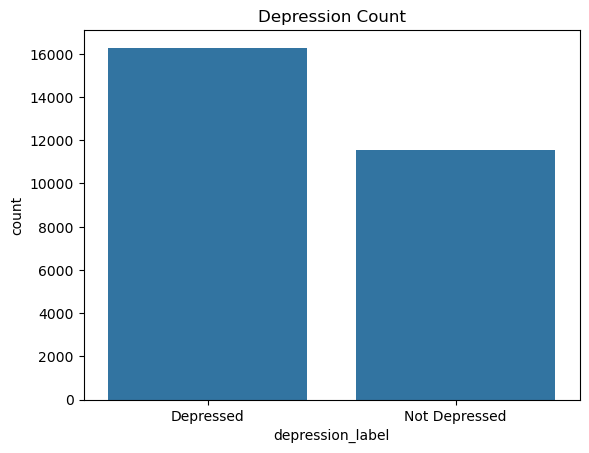

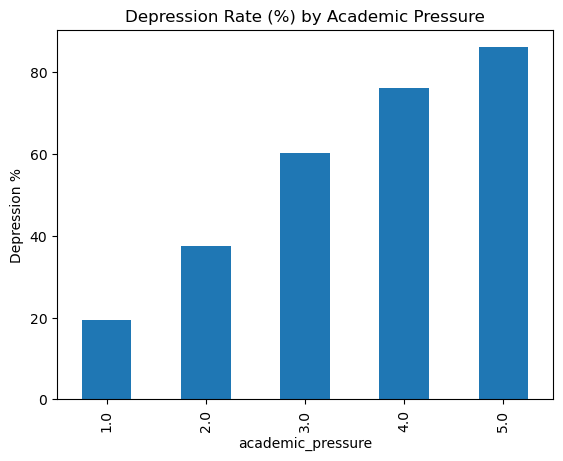

In [15]:
# Chart 1: how many students are depressed
sns.countplot(x="depression_label", data=df)
plt.title("Depression Count")
plt.show()

# Chart 2: depression rate by academic pressure
rate = df.groupby("academic_pressure")["depression"].mean() * 100
rate.plot(kind="bar")
plt.title("Depression Rate (%) by Academic Pressure")
plt.ylabel("Depression %")
plt.show()

**Insight:** 58.5% of students in the dataset are labelled depressed and 41.5% are not.

In [16]:
# 1. See how many rows are affected
print("cgpa = 0:", (df["cgpa"] == 0).sum())
print("academic_pressure = 0:", (df["academic_pressure"] == 0).sum())
print("age > 35:", (df["age"] > 35).sum())

# 2. Remove invalid rows
df = df[(df["cgpa"] > 0) & (df["academic_pressure"] >= 1)]
df = df.reset_index(drop=True)
print("New shape:", df.shape)

# 3. Helper columns for charts
df["age_group"] = pd.cut(df["age"], bins=[17, 21, 25, 30, 60],
                         labels=["18-21", "22-25", "26-30", "31+"])
df["depression_label"] = df["depression"].map({0: "Not Depressed", 1: "Depressed"})

# 4. Percentage of depressed vs not depressed
print(df["depression"].value_counts(normalize=True) * 100)

cgpa = 0: 0
academic_pressure = 0: 0
age > 35: 37
New shape: (27828, 19)
depression
1    58.523789
0    41.476211
Name: proportion, dtype: float64


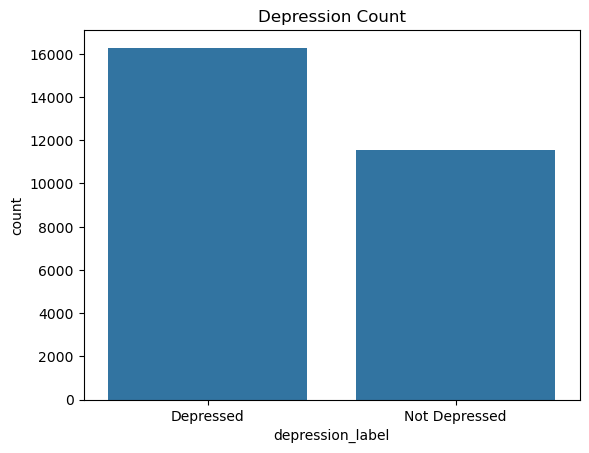

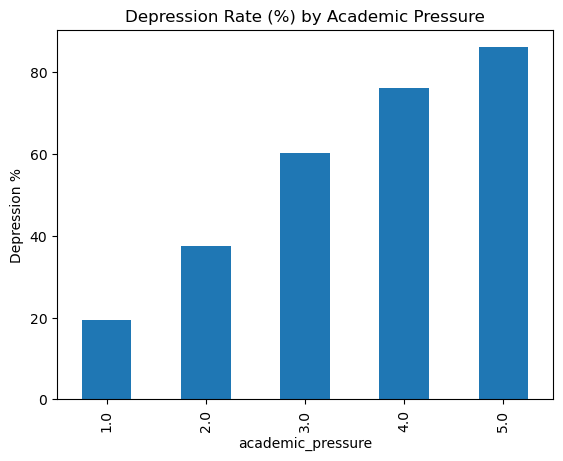

In [17]:
sns.countplot(x="depression_label", data=df)
plt.title("Depression Count")
plt.show()

rate = df.groupby("academic_pressure")["depression"].mean() * 100
rate.plot(kind="bar")
plt.title("Depression Rate (%) by Academic Pressure")
plt.ylabel("Depression %")
plt.show()

**Insights:**
- **Academic pressure:** the depression rate rises at every level, from 19.4% (level 1) to 86.1% (level 5). It is the strongest factor.
- **Financial stress:** the rate rises from 31.8% (level 1) to 81.2% (level 5).

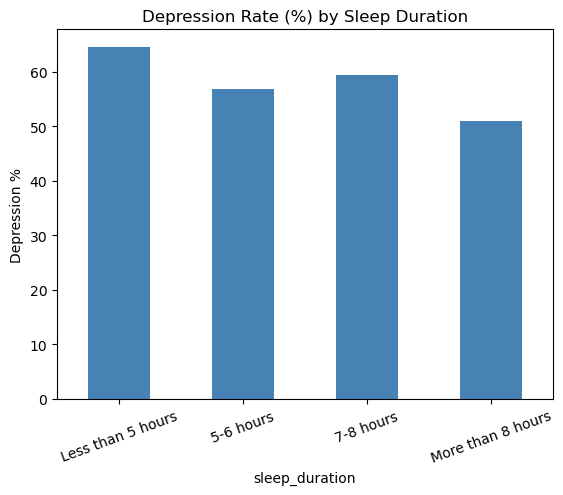

sleep_duration
Less than 5 hours    64.5
5-6 hours            56.9
7-8 hours            59.5
More than 8 hours    50.9
Name: depression, dtype: float64


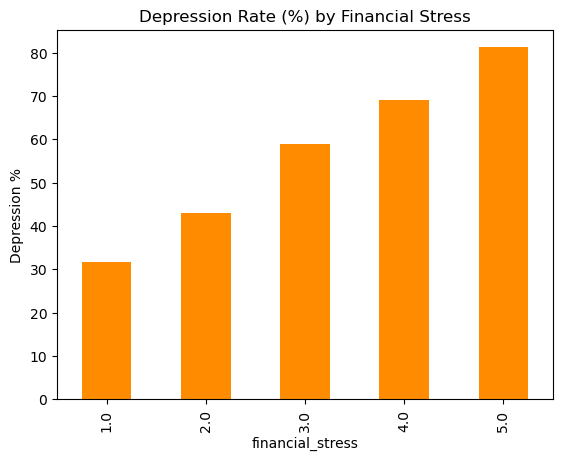

financial_stress
1.0    31.8
2.0    43.0
3.0    58.9
4.0    69.1
5.0    81.2
Name: depression, dtype: float64


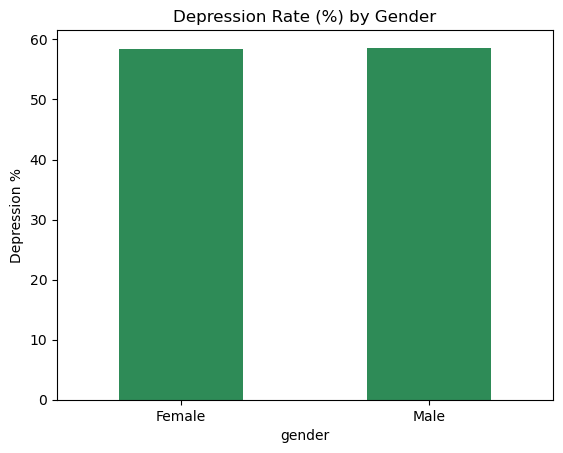

gender
Female    58.4
Male      58.6
Name: depression, dtype: float64


In [18]:
# 1. Depression rate by sleep duration
sleep_order = ["Less than 5 hours", "5-6 hours", "7-8 hours", "More than 8 hours"]
sleep_rate = (df.groupby("sleep_duration")["depression"].mean() * 100).reindex(sleep_order)
sleep_rate.plot(kind="bar", color="steelblue")
plt.title("Depression Rate (%) by Sleep Duration")
plt.ylabel("Depression %")
plt.xticks(rotation=20)
plt.show()
print(sleep_rate.round(1))

# 2. Depression rate by financial stress
fin_rate = df.groupby("financial_stress")["depression"].mean() * 100
fin_rate.plot(kind="bar", color="darkorange")
plt.title("Depression Rate (%) by Financial Stress")
plt.ylabel("Depression %")
plt.show()
print(fin_rate.round(1))

# 3. Depression rate by gender
gender_rate = df.groupby("gender")["depression"].mean() * 100
gender_rate.plot(kind="bar", color="seagreen")
plt.title("Depression Rate (%) by Gender")
plt.ylabel("Depression %")
plt.xticks(rotation=0)
plt.show()
print(gender_rate.round(1))

**Insights:**
- **Academic pressure:** the depression rate rises at every level, from 19.4% (level 1) to 86.1% (level 5). It is the strongest factor.
- **Financial stress:** the rate rises from 31.8% (level 1) to 81.2% (level 5).

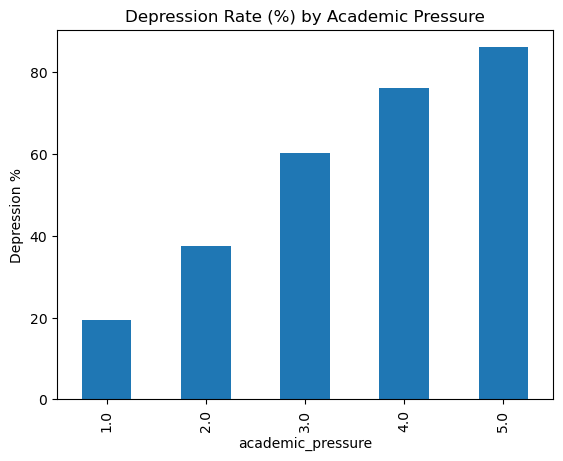

academic_pressure
1.0    19.4
2.0    37.4
3.0    60.1
4.0    76.1
5.0    86.1
Name: depression, dtype: float64 



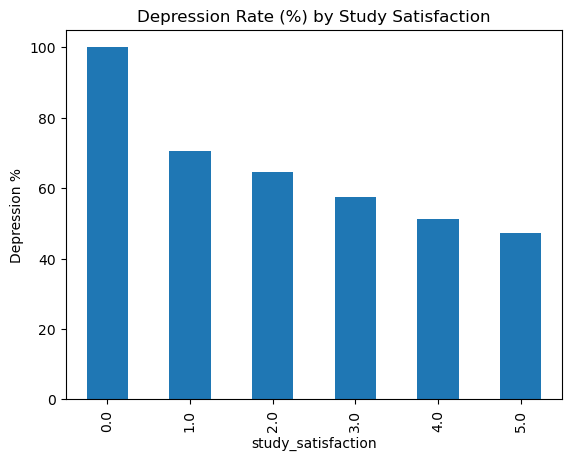

study_satisfaction
0.0    100.0
1.0     70.7
2.0     64.6
3.0     57.5
4.0     51.3
5.0     47.2
Name: depression, dtype: float64 



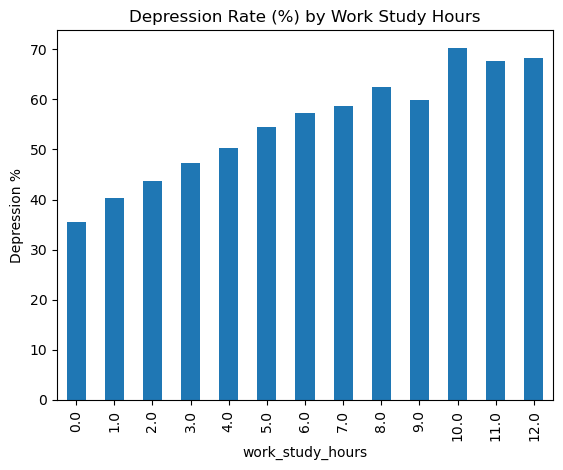

work_study_hours
0.0     35.5
1.0     40.3
2.0     43.7
3.0     47.3
4.0     50.3
5.0     54.5
6.0     57.3
7.0     58.7
8.0     62.5
9.0     59.9
10.0    70.4
11.0    67.7
12.0    68.4
Name: depression, dtype: float64 



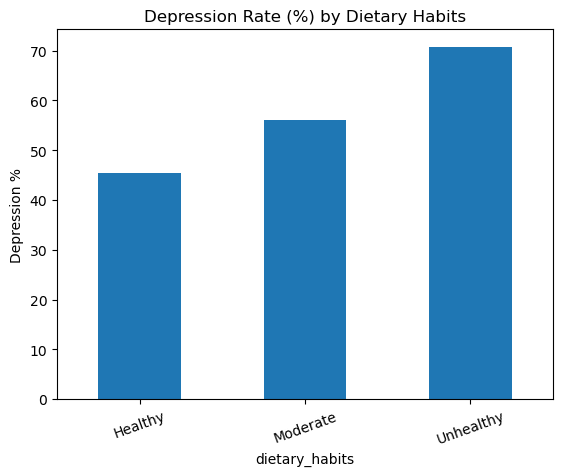

dietary_habits
Healthy      45.3
Moderate     56.0
Unhealthy    70.7
Name: depression, dtype: float64 



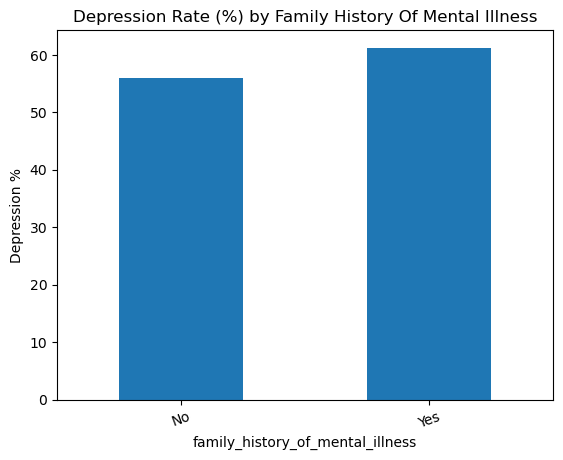

family_history_of_mental_illness
No     56.0
Yes    61.2
Name: depression, dtype: float64 



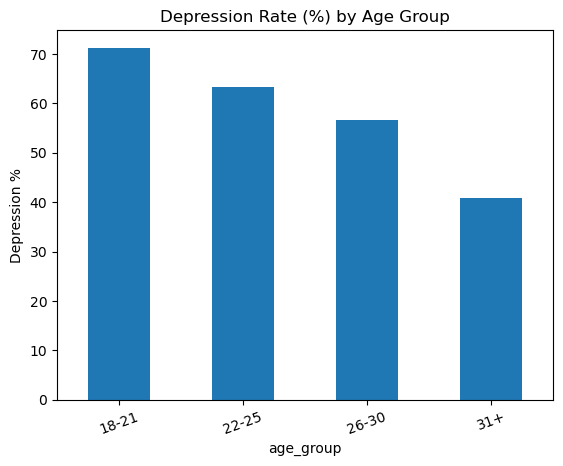

age_group
18-21    71.2
22-25    63.4
26-30    56.5
31+      40.8
Name: depression, dtype: float64 



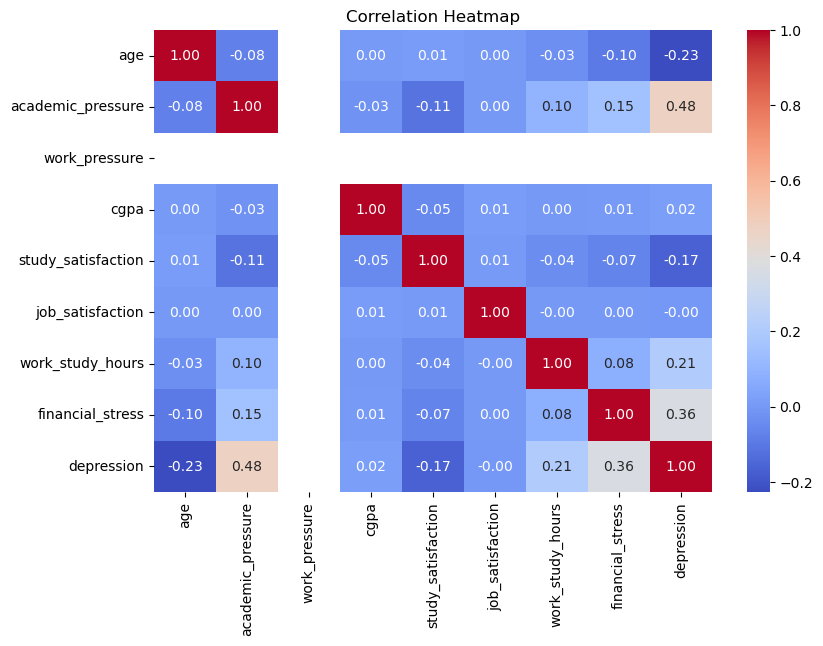

In [19]:
# Academic pressure, study satisfaction, work/study hours
for col in ["academic_pressure", "study_satisfaction", "work_study_hours"]:
    rate = df.groupby(col)["depression"].mean() * 100
    rate.plot(kind="bar")
    plt.title(f"Depression Rate (%) by {col.replace('_', ' ').title()}")
    plt.ylabel("Depression %")
    plt.show()
    print(rate.round(1), "\n")

# Dietary habits, family history, age group
for col in ["dietary_habits", "family_history_of_mental_illness", "age_group"]:
    rate = df.groupby(col, observed=True)["depression"].mean() * 100
    rate.plot(kind="bar")
    plt.title(f"Depression Rate (%) by {col.replace('_', ' ').title()}")
    plt.ylabel("Depression %")
    plt.xticks(rotation=20)
    plt.show()
    print(rate.round(1), "\n")

# Correlation heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [20]:
# 1. Check the odd 100% at study satisfaction = 0
print((df["study_satisfaction"] == 0).sum(), "students have study_satisfaction = 0")

# 2. Correlation of every number column with depression
corr = df.corr(numeric_only=True)["depression"].drop("depression").sort_values(ascending=False)
print(corr.round(2))

2 students have study_satisfaction = 0
academic_pressure     0.48
financial_stress      0.36
work_study_hours      0.21
cgpa                  0.02
job_satisfaction     -0.00
study_satisfaction   -0.17
age                  -0.23
work_pressure          NaN
Name: depression, dtype: float64


## Model Results (Random Forest)
- **Accuracy: 84.1%** (precision 0.85 and recall 0.88 for depressed students).
- Top features: suicidal thoughts (0.210), academic pressure (0.157), financial stress (0.101), CGPA (0.091), age (0.086).
- Without the suicidal thoughts column, accuracy is **78.7%**, and the top features are academic pressure (0.200), financial stress (0.127), CGPA (0.120), age (0.108), and work/study hours (0.098).
- Academic pressure and financial stress are the strongest factors in the tables, the correlations, and the model.
- CGPA ranks high in the model but has almost no simple correlation with depression, so no direct link is claimed.

Accuracy: 0.841
              precision    recall  f1-score   support

           0       0.82      0.79      0.80      2309
           1       0.85      0.88      0.87      3257

    accuracy                           0.84      5566
   macro avg       0.84      0.83      0.83      5566
weighted avg       0.84      0.84      0.84      5566



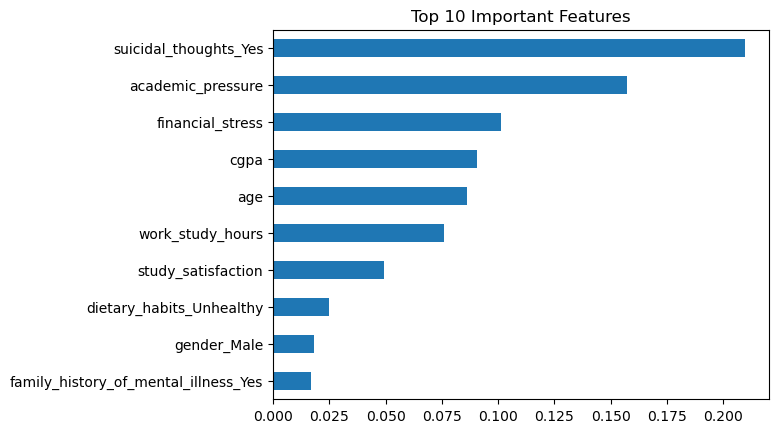

family_history_of_mental_illness_Yes    0.017
gender_Male                             0.018
dietary_habits_Unhealthy                0.025
study_satisfaction                      0.049
work_study_hours                        0.076
age                                     0.086
cgpa                                    0.091
financial_stress                        0.101
academic_pressure                       0.157
suicidal_thoughts_Yes                   0.210
dtype: float64


In [21]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Drop columns with no useful information
data = df.drop(columns=["work_pressure", "job_satisfaction", "profession",
                        "city", "depression_label", "age_group"])

X = pd.get_dummies(data.drop(columns=["depression"]), drop_first=True)
y = data["depression"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=200, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred))

imp = pd.Series(model.feature_importances_, index=X.columns).sort_values()
imp.tail(10).plot(kind="barh", title="Top 10 Important Features")
plt.show()
print(imp.tail(10).round(3))

Accuracy without that column: 0.787


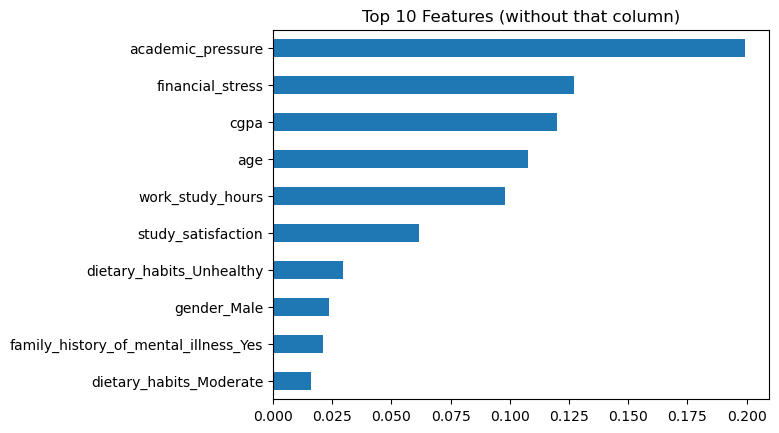

dietary_habits_Moderate                 0.016
family_history_of_mental_illness_Yes    0.021
gender_Male                             0.023
dietary_habits_Unhealthy                0.030
study_satisfaction                      0.062
work_study_hours                        0.098
age                                     0.108
cgpa                                    0.120
financial_stress                        0.127
academic_pressure                       0.200
dtype: float64


In [22]:
X2 = X.drop(columns=[c for c in X.columns if "suicidal" in c])
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y)

model2 = RandomForestClassifier(n_estimators=200, random_state=42)
model2.fit(X2_train, y2_train)
print("Accuracy without that column:", round(accuracy_score(y2_test, model2.predict(X2_test)), 3))

imp2 = pd.Series(model2.feature_importances_, index=X2.columns).sort_values()
imp2.tail(10).plot(kind="barh", title="Top 10 Features (without that column)")
plt.show()
print(imp2.tail(10).round(3))

"Objective: To analyze the Student Depression dataset (27,828 students after cleaning) and identify which academic, lifestyle, and financial factors are most associated with depression, and to build a model that predicts depression at the group level."

## Recommendations
1. Colleges should manage academic workload and exam pressure.
2. Provide financial support, scholarships, and part-time options for students under financial stress.
3. Make counselling services easy to access and well advertised.
4. Run awareness programmes on sleep and healthy eating.
5. Give extra support to younger students (18-25), who show higher rates.

## Limitations
- The results show association, not cause and effect.
- The data is self-reported and may contain bias.
- Some groups are very small (for example, 2 students with study satisfaction 0).
- The model finds patterns across groups of students. It must not be used to label any individual.

## Conclusion
Academic pressure and financial stress are the strongest factors linked with student depression in this dataset. Sleep, diet, study hours, and age also show clear patterns, while gender and CGPA show little or no link. Reducing pressure and improving support can help student wellbeing.